# Computational efficiency table (slide)

A 16:9 slide image of model cost vs focus-species accuracy for the six configurations.

**Sources.**
- **Parameters and GFLOPs:** Ultralytics model summaries, with GFLOPs at 1280 px input.
- **Inference time:** median per-image forward pass recorded during test-fold evaluation on one NVIDIA H100 at batch size 8 (20 runs per model), excluding pre-processing (≈1 ms) and post-processing (0.1–0.3 ms). Baseline and augmented models have the same architecture and inference time.
- **Training time:** mean seconds per epoch over 10 runs.
- **Focus-species AP50:** pooled out-of-fold test predictions, seeds averaged. Detection uses box IoU and segmentation uses mask IoU.

Edit `ROWS`, `HIGHLIGHT` or the footnote text, then rerun. Set `THEME` to `'light'` or `'dark'`.

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

THEME = 'light'
SAVE = True
DPI = 150

## Data

In [2]:
# model, params (M), GFLOPs @1280, inference ms/image (H100), train s/epoch (baseline, augmented), focus AP50 (baseline, augmented)
ROWS = [
    ('Detection S',    10.0,  95, 2.0, (10.3, 15.4), (0.267, 0.357)),
    ('Detection M',    21.9, 305, 3.2, (16.3, 24.4), (0.335, 0.424)),
    ('Detection L',    26.3, 380, 4.1, (22.4, 33.8), (0.373, 0.440)),
    ('Segmentation S', 11.5, 153, 2.3, (15.1, 22.8), (0.239, 0.355)),
    ('Segmentation M', 27.1, 533, 4.1, (24.0, 36.2), (0.308, 0.458)),
    ('Segmentation L', 31.5, 609, 4.9, (29.6, 44.5), (0.361, 0.444)),
]
HIGHLIGHT = {'Detection M': 'aug', 'Detection L': 'base'}   # cells to emphasise (augmented Det M beats baseline Det L)
TOTAL_GPU_HOURS = 84.6

## Style

In [3]:
THEMES = {
    'light': dict(bg='#ffffff', ink='#0b0b0b', ink2='#52514e', grid='#e1e0d9', head='#f4f3ef', orange='#eb6834', blue='#2a78d6'),
    'dark':  dict(bg='#0f1b2d', ink='#f0efec', ink2='#c3c2b7', grid='#26354b', head='#18283f', orange='#e2683a', blue='#4a90e8'),
}
T = THEMES[THEME]
plt.rcParams.update({'font.family': 'DejaVu Sans', 'figure.facecolor': T['bg'], 'savefig.facecolor': T['bg']})

## Table

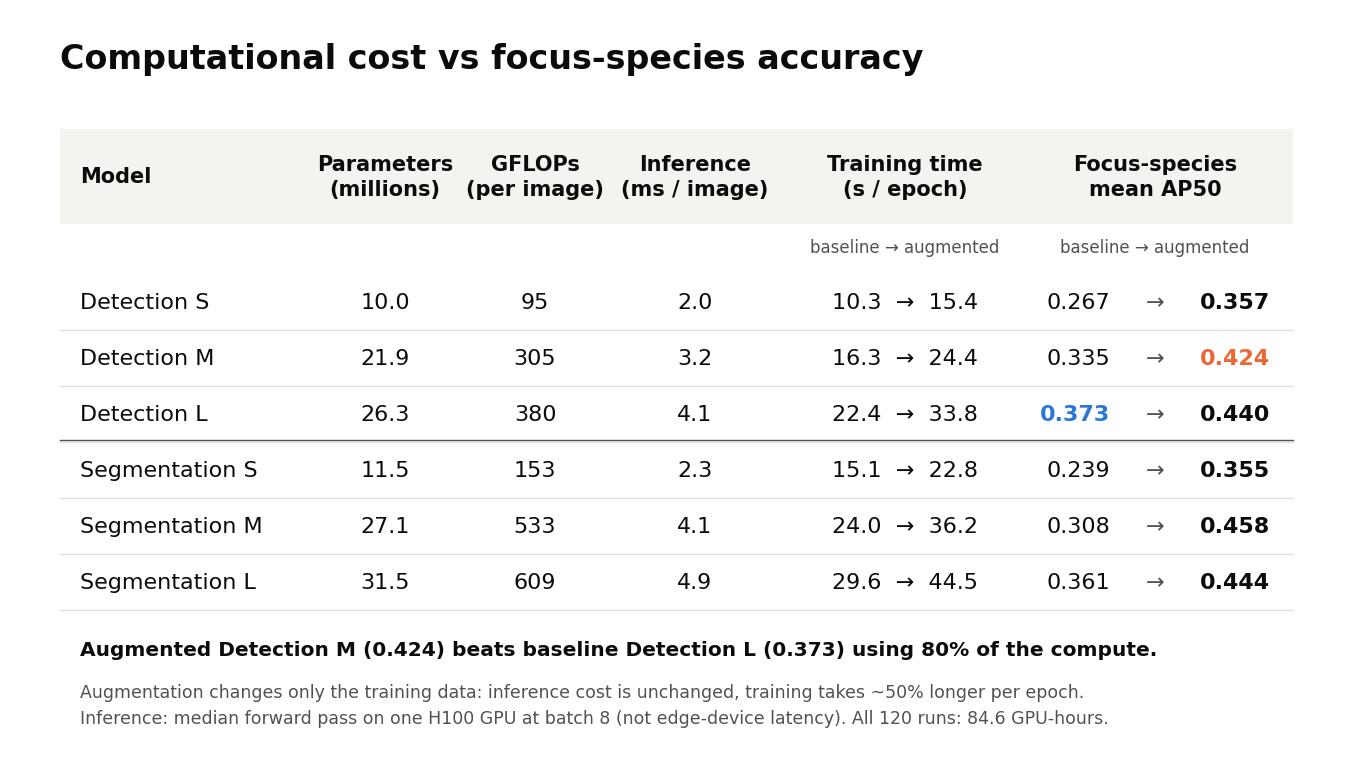

In [4]:
fig = plt.figure(figsize=(13.33, 7.5)); ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, 13.33); ax.set_ylim(0, 7.5); ax.axis('off')

ax.text(0.5, 7.0, 'Computational cost vs focus-species accuracy', fontsize=24, fontweight='bold', color=T['ink'], va='center')

# column x positions (centres) and headers
cols = [(1.55, 'Model', 'left'), (3.75, 'Parameters\n(millions)', 'center'), (5.25, 'GFLOPs\n(per image)', 'center'),
        (6.85, 'Inference\n(ms / image)', 'center'), (8.95, 'Training time\n(s / epoch)', 'center'),
        (11.45, 'Focus-species\nmean AP50', 'center')]
top, rh = 6.3, 0.56
ax.add_patch(Rectangle((0.5, top - 0.95), 12.33, 0.95, color=T['head'], lw=0))
for x, h, ha in cols:
    ax.text(0.7 if ha == 'left' else x, top - 0.475, h, ha=ha, va='center', fontsize=15, fontweight='bold', color=T['ink'], linespacing=1.3)
ax.text(8.95, top - 1.18, 'baseline → augmented', ha='center', va='center', fontsize=12, color=T['ink2'])
ax.text(11.45, top - 1.18, 'baseline → augmented', ha='center', va='center', fontsize=12, color=T['ink2'])

y = top - 1.45
for i, (name, p, g, inf, tr, ap) in enumerate(ROWS):
    yc = y - rh / 2
    if i == 3:  # divider between detection and segmentation
        ax.plot([0.5, 12.83], [y + 0.02, y + 0.02], color=T['ink2'], lw=1)
    ax.text(0.7, yc, name, ha='left', va='center', fontsize=16, color=T['ink'])
    ax.text(3.75, yc, f'{p:.1f}', ha='center', va='center', fontsize=16, color=T['ink'])
    ax.text(5.25, yc, f'{g}', ha='center', va='center', fontsize=16, color=T['ink'])
    ax.text(6.85, yc, f'{inf:.1f}', ha='center', va='center', fontsize=16, color=T['ink'])
    ax.text(8.95, yc, f'{tr[0]:.1f}  →  {tr[1]:.1f}', ha='center', va='center', fontsize=16, color=T['ink'])
    hb = HIGHLIGHT.get(name) == 'base'; ha_ = HIGHLIGHT.get(name) == 'aug'
    ax.text(11.0, yc, f'{ap[0]:.3f}', ha='right', va='center', fontsize=16,
            color=T['blue'] if hb else T['ink'], fontweight='bold' if hb else 'normal')
    ax.text(11.45, yc, '→', ha='center', va='center', fontsize=16, color=T['ink2'])
    ax.text(11.9, yc, f'{ap[1]:.3f}', ha='left', va='center', fontsize=16,
            color=T['orange'] if ha_ else T['ink'], fontweight='bold')
    ax.plot([0.5, 12.83], [y - rh, y - rh], color=T['grid'], lw=1)
    y -= rh

# take-home note
ax.text(0.7, y - 0.4, f'Augmented Detection M ({ROWS[1][5][1]:.3f}) beats baseline Detection L ({ROWS[2][5][0]:.3f}) '
        f'using {ROWS[1][2] / ROWS[2][2]:.0%} of the compute.',
        fontsize=14.5, color=T['ink'], va='center', fontweight='bold')
ax.text(0.7, y - 0.95, 'Augmentation changes only the training data: inference cost is unchanged, training takes ~50% longer per epoch.\n'
        f'Inference: median forward pass on one H100 GPU at batch 8 (not edge-device latency). All 120 runs: {TOTAL_GPU_HOURS} GPU-hours.',
        fontsize=12.5, color=T['ink2'], va='center', linespacing=1.5)
if SAVE:
    for ext in ('png', 'pdf'): fig.savefig(f'efficiency_table_{THEME}.{ext}', dpi=DPI)
plt.show()